In [1]:
import numpy as np
import agama
agama.setUnits(length=1, velocity=1, mass=1)  # kpc, km/s, Solar mass
import matplotlib.pyplot as plt
from IPython.display import Latex
import sys
sys.path.append('/suphys/aani0116/Work/minicluster_model_new/my_modules/')

from scipy.stats import uniform_direction
from reverse_orbit import reverse_orbit
from mc_declare import *
pot_mw = agama.Potential('/suphys/aani0116/minicluster/minicluster_tidal/Agama/data/McMillan17.ini')
sys.path.append('/suphys/aani0116/Work/minicluster_tidal/stellar')
from N_calculator import N_encounter 
from N_calculator import stellar_rho_total
from scipy.integrate import quad
from hmf import get_mass
from times import dynamical_time
from mass_loss_new import *
from generate_particles import *
from radius_and_energy import *
from sklearn.decomposition import PCA
import corner
from mc_xv import generate_xv_at,generate_xv

kappa=3.54
beta=3.47


In [2]:
def get_b(N):
    b = np.sqrt(np.random.uniform(0, (1e-4)**2, N))
    return b

In [3]:
def get_b_uniform(N):
    b = np.random.uniform(0, 1e-4, N)
    return b

In [4]:
N=10000
b1 = get_b(10000)
b2 = get_b_uniform(10000)

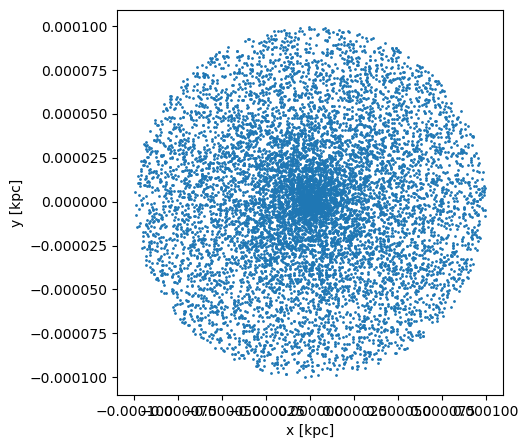

In [5]:
b = b2
phi = np.random.uniform(0, 2*np.pi, N)

plt.figure(figsize=(5, 5))
plt.scatter(b*np.cos(phi), b*np.sin(phi), s=1)
plt.gca().set_aspect('equal')
plt.xlabel('x [kpc]'); plt.ylabel('y [kpc]')
plt.show()



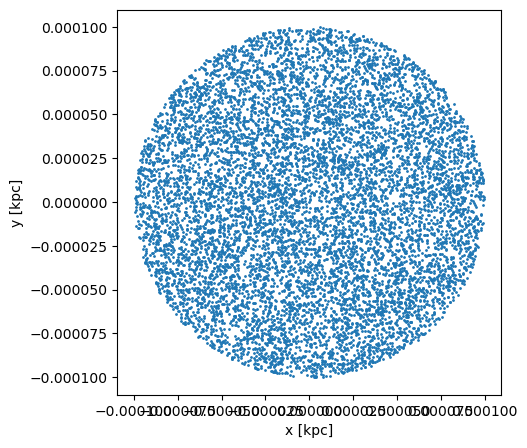

In [6]:
b = get_b(N)
phi = np.random.uniform(0, 2*np.pi, N)

plt.figure(figsize=(5, 5))
plt.scatter(b*np.cos(phi), b*np.sin(phi), s=1)
plt.gca().set_aspect('equal')
plt.xlabel('x [kpc]'); plt.ylabel('y [kpc]')
plt.show()



In [7]:
#Check energy

In [8]:
def stellar_energy(N,M,R,v,its_sum,r1,r2):
    #b=np.random.uniform(100*R, 1e-4,N) #is this a good choice?
    np.random.seed(42)
    b = np.sqrt(np.random.default_rng(42).uniform(r1**2, (r2)**2, N))
    E=((4*agama.G*agama.G*M*0.27*R*R)/(((b**4)*v**2)*3))
    E_sum=np.sum(E)
    print(E_sum)
    E_rms_sum=(np.sum(np.sqrt(E)))**2
    print(E_rms_sum)
    if its_sum:
        return E_sum,b
    else:
        return E_rms_sum,b

In [9]:
def N_encounter_new(t,xv, b_max=1e-4): #stellar_rho_total use the better model
    return np.trapezoid(stellar_rho_total(xv[:,0], xv[:,1], xv[:,2]) * np.linalg.norm(xv[:, 3:],axis=1) * np.pi  * b_max**2,t)

In [10]:
mc = Minicluster(mass=get_mass(), delta=50, concentration=10)
mc.mass,mc.radius

(9.049032407826591e-15, 1.6758441058281605e-12)

In [11]:
t,xv=agama.orbit(ic=[8,0,0,0,1,220], potential=pot_mw, time=1e-2, timestart=0, dtype=float, trajsize=10,accuracy=1e-10, verbose=False)

1135
6.63806618435688e-32
2.969652687424407e-30
6.63806618435688e-32


(array([ 17.,  45.,  49., 105.,  91., 118., 147., 159., 193., 211.]),
 array([3.51149898e-06, 1.31574582e-05, 2.28034174e-05, 3.24493767e-05,
        4.20953359e-05, 5.17412951e-05, 6.13872544e-05, 7.10332136e-05,
        8.06791728e-05, 9.03251321e-05, 9.99710913e-05]),
 <BarContainer object of 10 artists>)

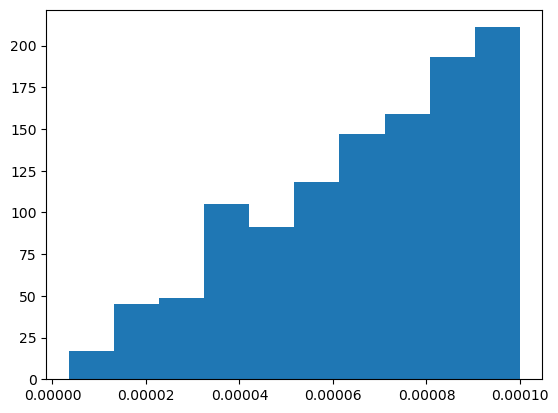

In [12]:
N0=N_encounter_new(t,xv,1e-4)
print(int(N0))
E0,b0=stellar_energy(int(N0),mc.mass,mc.radius,200,1,0,1e-4)
print(E0)
plt.hist(b0)

In [13]:
rout=1e-3
N1=N_encounter_new(t,xv,rout)
Nout=N1-N0
E1,b1=stellar_energy(int(Nout),mc.mass,mc.radius,200,1,1e-4,rout)

4.851016851111236e-35
1.163617131789489e-30


In [14]:
rout=1e-2
N10=N_encounter_new(t,xv,rout)
Nout=N10-N0
E10,b10=stellar_energy(int(Nout),mc.mass,mc.radius,200,1,1e-4,rout)

4.7476758016689814e-35
4.616207610393731e-30


In [15]:
rout=1e-1
N100=N_encounter_new(t,xv,rout)
Nout=N100-N0
E100,b100=stellar_energy(int(Nout),mc.mass,mc.radius,200,1,1e-4,rout)

4.779911131138294e-35
1.0403350761618114e-29


In [16]:
E=[E0,E0+E1,E0+E10,E0+E100] #naming wrong,e10 is 1pc
d=[0.1,1,10,100]

Text(0.5, 1.0, 'Energy vs distance for E_sum')

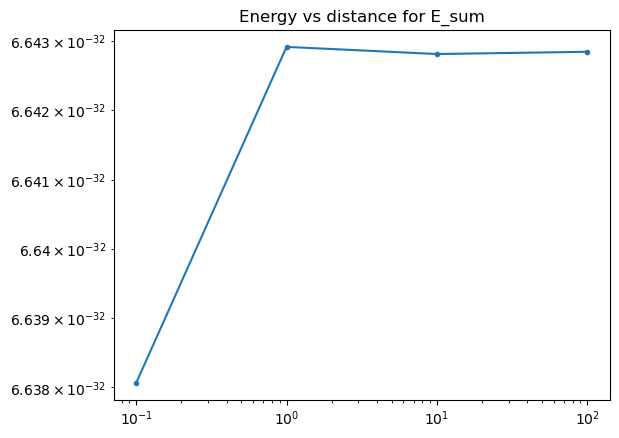

In [17]:
plt.loglog(d,E,marker='.')
plt.title('Energy vs distance for E_sum')

In [18]:
#energy vs distance for E_rms

In [19]:
mc = Minicluster(mass=get_mass(), delta=50, concentration=10)
mc.mass,mc.radius
t,xv=agama.orbit(ic=[8,0,0,0,1,220], potential=pot_mw, time=1e-2, timestart=0, dtype=float, trajsize=10,accuracy=1e-10, verbose=False)

1135
3.7577730910665797e-32
1.6811042024429803e-30


(array([ 17.,  45.,  49., 105.,  91., 118., 147., 159., 193., 211.]),
 array([3.51149898e-06, 1.31574582e-05, 2.28034174e-05, 3.24493767e-05,
        4.20953359e-05, 5.17412951e-05, 6.13872544e-05, 7.10332136e-05,
        8.06791728e-05, 9.03251321e-05, 9.99710913e-05]),
 <BarContainer object of 10 artists>)

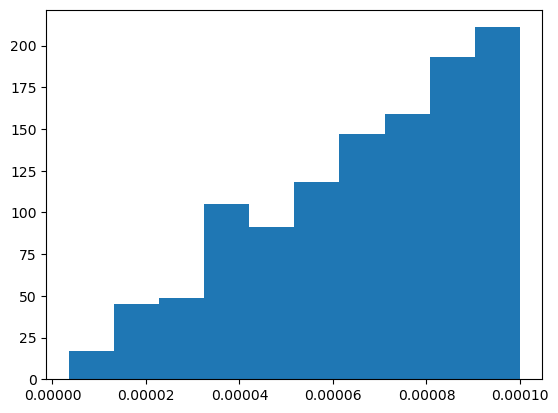

In [20]:
N0=N_encounter_new(t,xv,1e-4)
print(int(N0))
E0,b0=stellar_energy(int(N0),mc.mass,mc.radius,200,0,0,1e-4)
plt.hist(b0)

In [21]:
rout=1e-3
N1=N_encounter_new(t,xv,rout)
E1,b1=stellar_energy(int(N1),mc.mass,mc.radius,200,0,0,rout)

5.028691527717212e-32
5.569527720266846e-30


In [22]:
rout=1e-2
N10=N_encounter_new(t,xv,rout)
E10,b10=stellar_energy(int(N10),mc.mass,mc.radius,200,0,0,rout)

1.1365009299565036e-31
9.163522968813952e-30


In [23]:
rout=1e-1
N100=N_encounter_new(t,xv,rout)
E100,b100=stellar_energy(int(N100),mc.mass,mc.radius,200,0,0,rout)

7.231413401932694e-31
1.9816950813691346e-29


In [24]:
rout=2e-1
N200=N_encounter_new(t,xv,rout)
E200,b200=stellar_energy(int(N200),mc.mass,mc.radius,200,0,0,rout)

6.344910294902386e-32
1.5784488074539626e-29


Text(0.5, 1.0, 'Energy vs distance for E_sum')

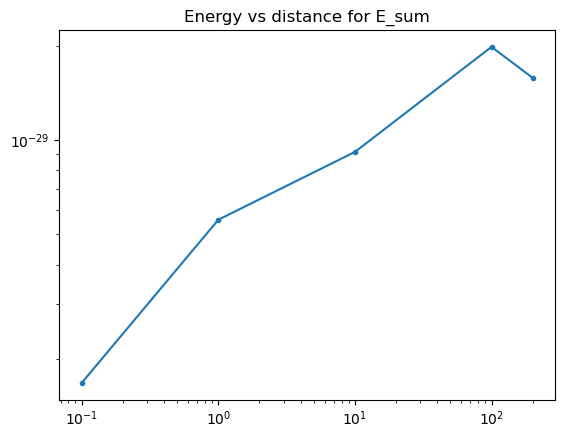

In [25]:
E=[E0,E1,E10,E100,E200] #naming wrong,e10 is 1pc
d=[0.1,1,10,100,200]
plt.loglog(d,E,marker='.')
plt.title('Energy vs distance for E_sum')

In [28]:
E_total

np.float64(6.037378089412901e-26)

In [33]:
def N_encounter_new(t,xv, b_max=1e-4): #stellar_rho_total use the better model
    return np.trapezoid(stellar_rho_total(xv[:,0], xv[:,1], xv[:,2]) * np.linalg.norm(xv[:, 3:],axis=1) * np.pi  * b_max**2,t)
def stellar_energy(N,M,R,v,its_sum,r1,r2):
    #b=np.random.uniform(100*R, 1e-4,N) #is this a good choice?
    np.random.seed(42)
    b = np.sqrt(np.random.default_rng(42).uniform(r1**2, (r2)**2, N))
    E=((4*agama.G*agama.G*M*0.27*R*R)/(((b**4)*v**2)*3))
    E_sum=np.sum(E)
    print(E_sum)
    E_rms_sum=(np.sum(np.sqrt(E)))**2
    print(E_rms_sum)
    if its_sum:
        return E_sum,b
    else:
        return E_rms_sum,b,E

In [34]:
mc = Minicluster(mass=get_mass(), delta=50, concentration=10)
mc.mass,mc.radius
t,xv=agama.orbit(ic=[8,0,0,0,1,220], potential=pot_mw, time=1e-2, timestart=0, dtype=float, trajsize=10,accuracy=1e-10, verbose=False)

In [36]:
N0=N_encounter_new(t,xv,1e-4)
print(int(N0))
E0,b0,E=stellar_energy(int(N0),mc.mass,mc.radius,200,0,0,1e-4)


1135
3.7577730910665797e-32
1.6811042024429803e-30


In [44]:
E0

np.float64(1.6811042024429803e-30)

In [42]:
E_sum=(np.sqrt(E[:-1])+np.sqrt(E[1:]))**2

In [43]:
np.sum(E_sum)

np.float64(7.807602053412672e-32)